# Análisis exploratorio — La industria espacial en cifras

Proyecto **Órbita**: datos de todos los lanzamientos orbitales desde 1957
hasta hoy, obtenidos de la API pública **Launch Library 2** (The Space Devs).

Este cuaderno responde a preguntas como:

- ¿Cuántos lanzamientos ha habido y cómo ha evolucionado la actividad?
- ¿Qué agencias dominan el sector y con qué fiabilidad?
- ¿Qué cohetes son los más usados y los más fiables?
- ¿Hacia qué órbitas se lanza y desde dónde?
- ¿Cuántas personas han volado al espacio?
- ¿Qué lanzamientos nos esperan en los próximos meses?

Cada sección termina con una conclusión. Datos descargados el 25/10/2026; la tasa de éxito se calcula solo sobre lanzamientos ya realizados (éxito, fallo o fallo parcial), sin contar los programados.


## 0. Preparación

Cargamos las librerías y un helper para leer la base de datos SQLite.


In [1]:
import sqlite3
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo y opciones de visualización
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 95
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

DB = "../data/espacio.db"


def query(sql, params=None):
    """Ejecuta una consulta y devuelve un DataFrame."""
    conn = sqlite3.connect(DB)
    try:
        return pd.read_sql_query(sql, conn, params=params)
    finally:
        conn.close()


In [2]:
# Tablas de la base de datos
for tabla in ["launches", "agencies", "astronauts", "locations", "pads"]:
    n = query(f"SELECT COUNT(*) AS n FROM {tabla}").iloc[0, 0]
    print(f"{tabla:12s} -> {n:>7,} filas")


launches     ->   8,120 filas
agencies     ->     350 filas
astronauts   ->     862 filas
locations    ->      54 filas
pads         ->     240 filas


## 1. Primer vistazo a los lanzamientos

Cargamos todos los lanzamientos y preparamos la columna de fecha.


In [3]:
launch = query("SELECT * FROM launches")
print(f"{len(launch):,} lanzamientos registrados "
      f"(desde {launch['net'].min()} hasta {launch['net'].max()})")

# Fechas: eliminamos la 'Z' final y convertimos
launch["net_dt"] = pd.to_datetime(launch["net"], errors="coerce")
launch["anio"] = launch["net_dt"].dt.year
print(f"Lanzamientos con fecha válida: {launch['net_dt'].notna().sum():,}")
launch[["name", "net", "status_name", "rocket_name", "agency_name",
        "orbit"]].head(10)


8,120 lanzamientos registrados (desde 1957-10-04T19:28:34Z hasta 2039-12-31T00:00:00Z)
Lanzamientos con fecha válida: 8,120


,name,net,status_name,rocket_name,agency_name,orbit
0,Sputnik 8K74PS | Sputnik 1,1957-10-04T19:28:34Z,Success,Sputnik 8K74PS,Soviet Space Program,Low Earth Orbit
1,Sputnik 8K74PS | Sputnik 2,1957-11-03T02:30:00Z,Success,Sputnik 8K74PS,Soviet Space Program,Low Earth Orbit
2,Vanguard | Vanguard,1957-12-06T16:44:35Z,Failure,Vanguard,US Navy,Low Earth Orbit
3,Juno-I | Explorer 1,1958-02-01T03:47:56Z,Success,Juno-I,Army Ballistic Missile Agency,Low Earth Orbit
4,Vanguard | Vanguard,1958-02-05T07:33:00Z,Failure,Vanguard,US Navy,Low Earth Orbit
5,Juno-I | Explorer 2,1958-03-05T18:27:57Z,Failure,Juno-I,Army Ballistic Missile Agency,Low Earth Orbit
6,Vanguard | Vanguard,1958-03-17T12:15:41Z,Success,Vanguard,US Navy,Low Earth Orbit
7,Juno-I | Explorer 3,1958-03-26T17:38:01Z,Success,Juno-I,Army Ballistic Missile Agency,Elliptical Orbit
8,Sputnik 8A91 | D-1 1,1958-04-27T07:00:35Z,Failure,Sputnik 8A91,Soviet Space Program,Low Earth Orbit
9,Vanguard | Vanguard,1958-04-29T02:53:00Z,Failure,Vanguard,US Navy,Low Earth Orbit


In [4]:
# Estado y datos incompletos
print("Valores nulos por columna clave:")
launch[["name", "net", "status_name", "rocket_name",
        "agency_name", "orbit"]].isna().sum()


Valores nulos por columna clave:


name             0
net              0
status_name      0
rocket_name      0
agency_name      0
orbit          536
dtype: int64

## 2. Evolución histórica de los lanzamientos

De 3 lanzamientos en 1957 a 341 en 2025. Veamos la serie completa.


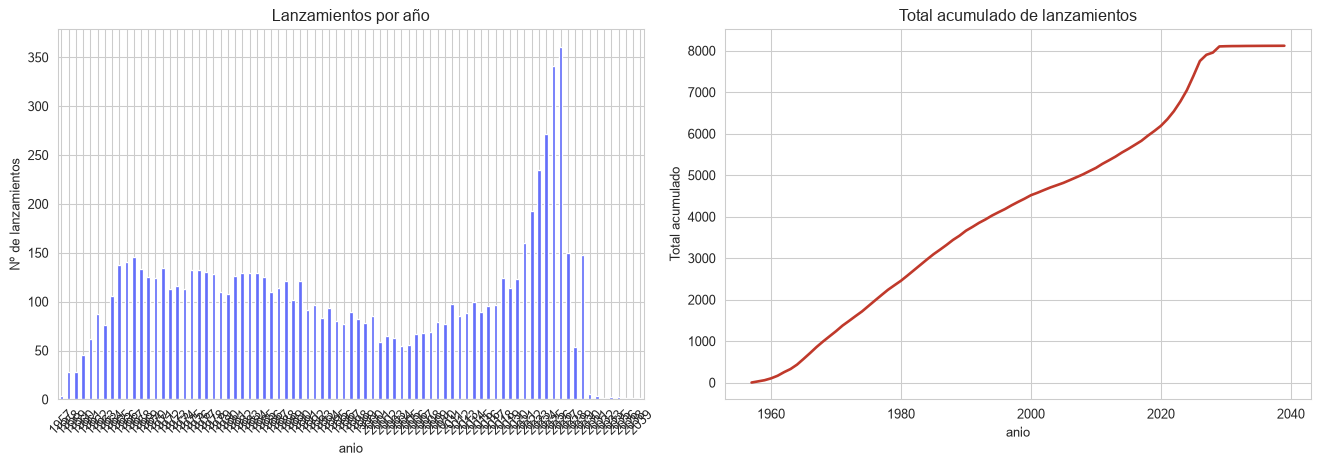

In [5]:
por_anio = launch.groupby("anio").size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
por_anio.plot(kind="bar", ax=axes[0], color="#636efa")
axes[0].set_title("Lanzamientos por año")
axes[0].set_ylabel("Nº de lanzamientos")
axes[0].tick_params(axis="x", rotation=45)

por_anio.cumsum().plot(ax=axes[1], color="#c0392b", linewidth=2)
axes[1].set_title("Total acumulado de lanzamientos")
axes[1].set_ylabel("Total acumulado")
plt.tight_layout()
plt.show()


In [6]:
# Crecimiento por década
decadas = (por_anio.index // 10 * 10).to_series(index=por_anio.index)
print(por_anio.groupby(decadas).sum().rename("lanzamientos"))


anio
1950      59
1960    1058
1970    1232
1980    1193
1990     891
2000     666
2010     968
2020    2037
2030      16
Name: lanzamientos, dtype: int64


**Conclusión 2:** la carrera espacial dejó un primer pico de actividad en los años 60-80 (hasta 146 lanzamientos en 1967). Después la actividad cayó, con un mínimo de 56 en 2005, y desde 2018 se ha disparado: 193 lanzamientos en 2022, 272 en 2024 y un récord de 341 en 2025. Entre 2016 y 2025 se hicieron 1.755 lanzamientos, más que en la década de mayor actividad soviética y estadounidense (1.277 entre 1966 y 1975).


## 3. Estados y tasa de éxito

¿Cuántos lanzamientos fracasan? Analizamos los estados y la tasa de éxito.


status_name
Success            7090
Failure             523
TBD                 469
Partial Failure      34
Go                    3
In Flight             1
Name: count, dtype: int64


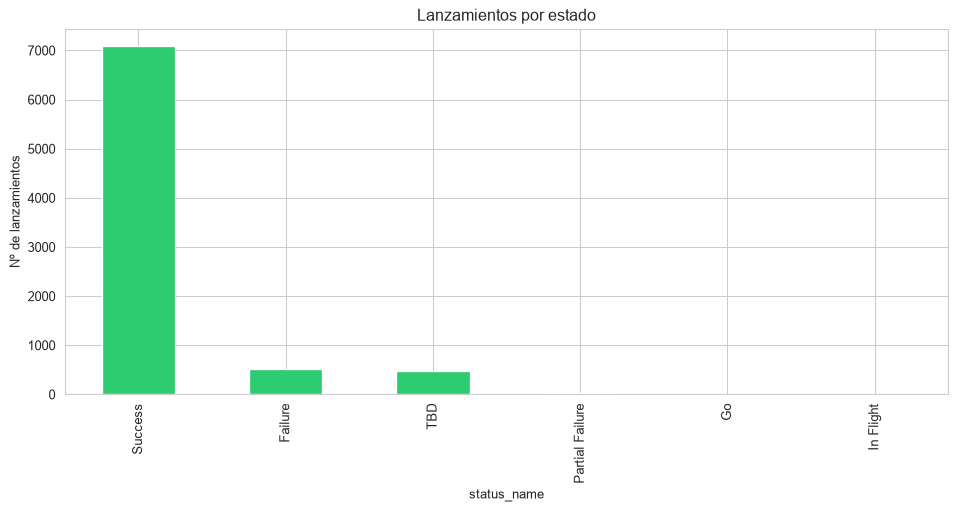

In [7]:
estados = launch["status_name"].value_counts()
print(estados)
estados.plot(kind="bar", color="#2ecc71")
plt.title("Lanzamientos por estado")
plt.ylabel("Nº de lanzamientos")
plt.show()


Tasa de éxito global: 92.7% (7,647 lanzamientos decididos)


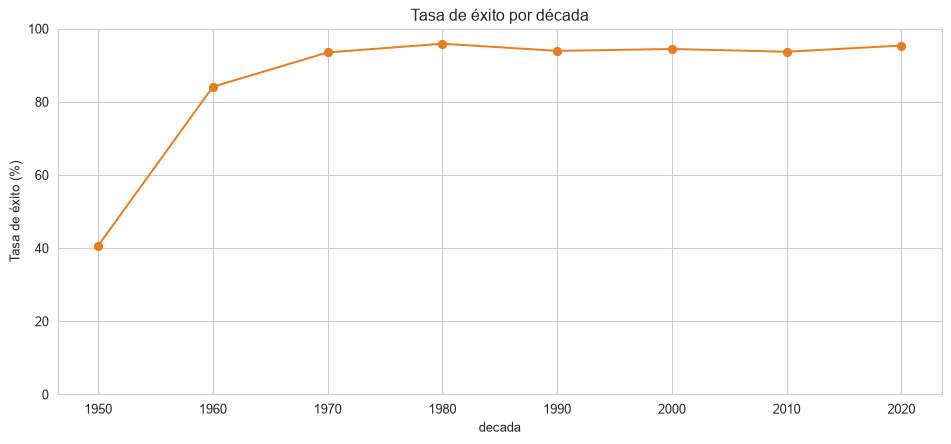

         total  exitos     tasa_%
decada                           
1950      59.0    24.0  40.677966
1960    1058.0   890.0  84.120983
1970    1232.0  1152.0  93.506494
1980    1193.0  1144.0  95.892707
1990     891.0   837.0  93.939394
2000     666.0   629.0  94.444444
2010     968.0   907.0  93.698347
2020    1580.0  1507.0  95.379747


In [8]:
# Tasa de éxito global (excluyendo los sin decidir: TBD/TBC/Go)
# Solo los lanzamientos ya resueltos: los futuros (TBD, Go...) no son éxitos ni fallos
RESUELTOS = ["Success", "Failure", "Partial Failure"]
decididos = launch[launch["status_name"].isin(RESUELTOS)].copy()
tasa_global = (decididos["status_name"] == "Success").mean() * 100
print(f"Tasa de éxito global: {tasa_global:.1f}% "
      f"({len(decididos):,} lanzamientos decididos)")

# Tasa de éxito por década
decididos["decada"] = (decididos["anio"] // 10 * 10)
por_decada = decididos.groupby("decada").apply(
    lambda d: pd.Series({
        "total": len(d),
        "exitos": (d["status_name"] == "Success").sum(),
        "tasa_%": (d["status_name"] == "Success").mean() * 100,
    }),
    include_groups=False,
)
por_decada.plot(y="tasa_%", kind="line", marker="o", color="#e67e22", legend=False)
plt.title("Tasa de éxito por década")
plt.ylabel("Tasa de éxito (%)")
plt.ylim(0, 100)
plt.show()
print(por_decada)


**Conclusión 3:** la tasa de éxito global es del 92,7 % sobre 7.647 lanzamientos ya realizados. En los años 50 apenas llegaba al 41 %; en los 60 subió al 84 % y desde los 70 se mantiene por encima del 93 %, con un 95,4 % en lo que va de la década de 2020.


## 4. ¿Quién domina el espacio? Las agencias

Las agencias de lanzamiento ordenadas por actividad y fiabilidad.


                                                    lanzamientos  resueltos  exitos      tasa_%
agency_name                                                                                    
Soviet Space Program                                        2453       2453    2285   93.151243
United States Air Force                                     1078       1078     972   90.166976
SpaceX                                                       877        741     726   97.975709
China Aerospace Science and Technology Corporation           628        620     604   97.419355
Arianespace                                                  379        328     313   95.426829
Russian Federal Space Agency (ROSCOSMOS)                     349        344     333   96.802326
United Launch Alliance                                       247        175     175  100.000000
Khrunichev State Research and Production Space ...           193        193     178   92.227979
Rocket Lab                              

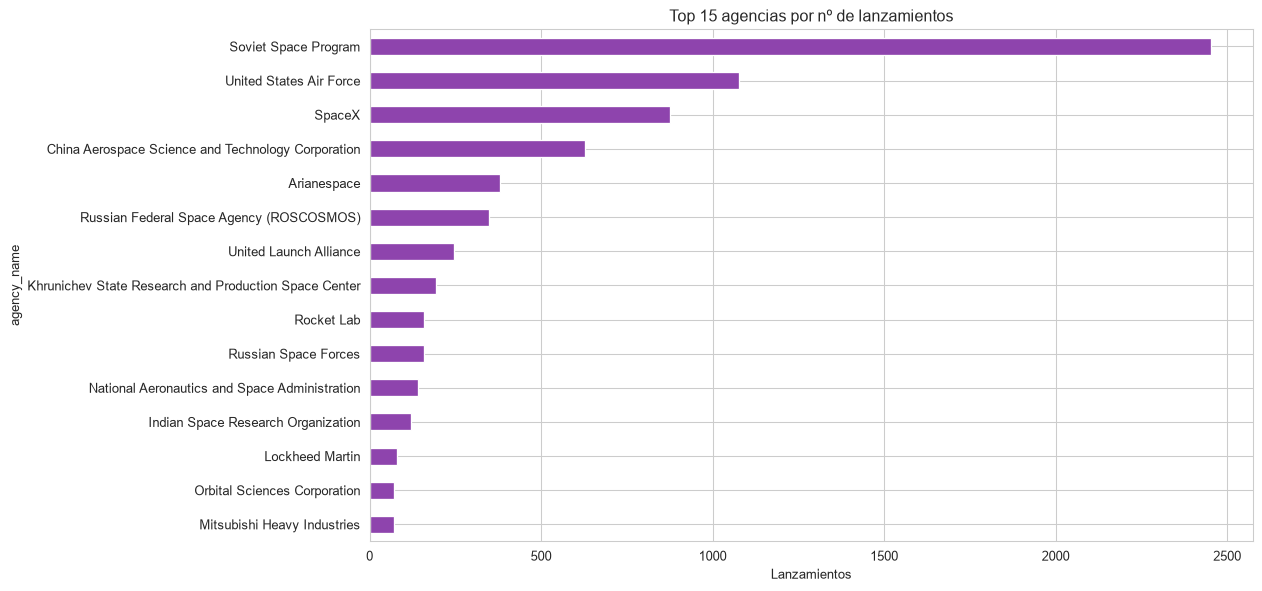

In [9]:
top_agencias = launch.groupby("agency_name").agg(
    lanzamientos=("id", "count"),
    resueltos=("status_name", lambda s: s.isin(RESUELTOS).sum()),
    exitos=("status_name", lambda s: (s == "Success").sum()),
).sort_values("lanzamientos", ascending=False).head(15)
top_agencias["tasa_%"] = top_agencias["exitos"] / top_agencias["resueltos"] * 100
print(top_agencias)

top_agencias["lanzamientos"].plot(kind="barh", color="#8e44ad", figsize=(12, 7))
plt.gca().invert_yaxis()
plt.title("Top 15 agencias por nº de lanzamientos")
plt.xlabel("Lanzamientos")
plt.show()


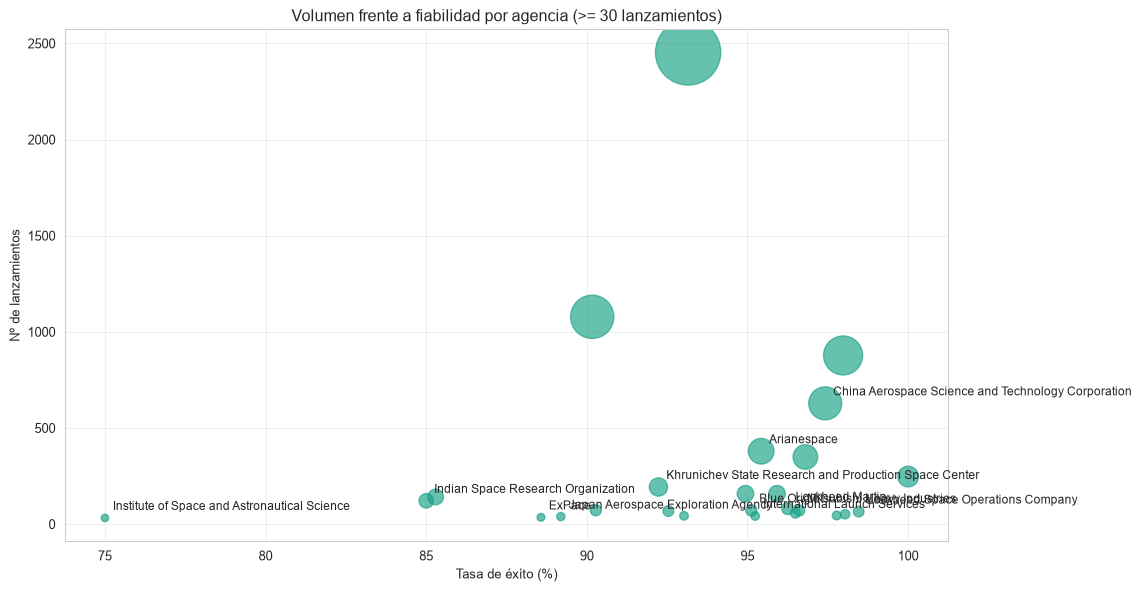

In [10]:
# Fiabilidad frente a volumen (solo agencias con >= 30 lanzamientos ya realizados)
activas = launch.groupby("agency_name").agg(
    lanzamientos=("id", "count"),
    resueltos=("status_name", lambda s: s.isin(RESUELTOS).sum()),
    exitos=("status_name", lambda s: (s == "Success").sum()),
).reset_index()
activas = activas[activas["resueltos"] >= 30].copy()
activas["tasa_%"] = activas["exitos"] / activas["resueltos"] * 100

plt.figure(figsize=(12, 7))
sc = plt.scatter(
    activas["tasa_%"], activas["lanzamientos"],
    s=activas["lanzamientos"], alpha=0.65, c="#16a085",
)
for _, f in activas.head(12).iterrows():
    plt.annotate(f["agency_name"], (f["tasa_%"], f["lanzamientos"]),
                 textcoords="offset points", xytext=(6, 6), fontsize=9)
plt.xlabel("Tasa de éxito (%)")
plt.ylabel("Nº de lanzamientos")
plt.title("Volumen frente a fiabilidad por agencia (>= 30 lanzamientos)")
plt.grid(True, alpha=0.3)
plt.show()


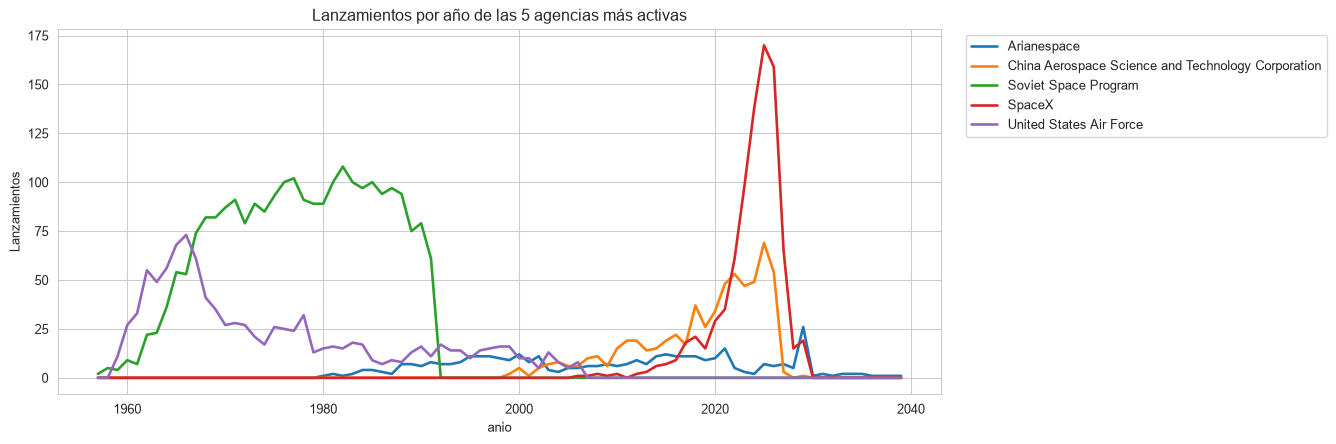

In [11]:
# Carrera de las 5 agencias más activas: lanzamientos por año
top5 = launch[launch["agency_name"].isin(top_agencias.index[:5])]
tabla = top5.pivot_table(index="anio", columns="agency_name",
                         values="id", aggfunc="count").fillna(0)
tabla.plot(kind="line", linewidth=2)
plt.title("Lanzamientos por año de las 5 agencias más activas")
plt.ylabel("Lanzamientos")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


**Conclusión 4:** el histórico lo dominan los programas estatales (2.453 lanzamientos del programa soviético y 1.078 de la Fuerza Aérea de EE. UU.), pero hoy el sector lo lidera **SpaceX**: desde 2021 ha hecho 624 lanzamientos, más que sus cuatro siguientes competidores juntos (492), y en toda su historia acumula un 98 % de éxito. La segunda potencia actual es China (CASC: 316 lanzamientos desde 2021 y un 97 % de éxito en toda su historia).


## 5. Los cohetes

¿Qué modelos acumulan más lanzamientos y cuáles son los más fiables?


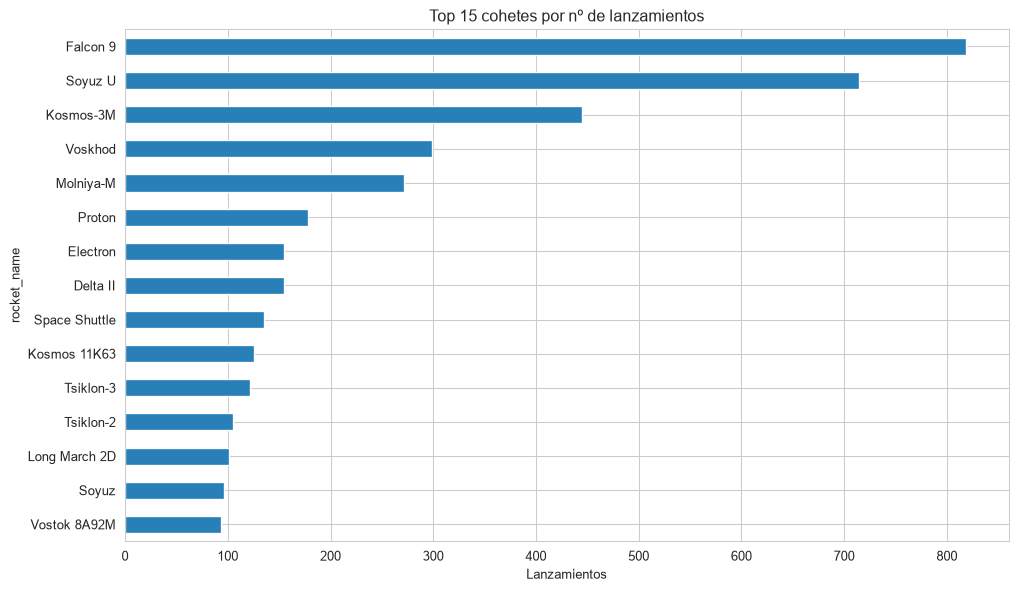

               lanzamientos  resueltos  exitos     tasa_%
rocket_name                                              
Falcon 9                819        699     695  99.427754
Soyuz U                 714        714     694  97.198880
Kosmos-3M               445        445     423  95.056180
Voskhod                 299        299     286  95.652174
Molniya-M               272        272     259  95.220588
Proton                  178        178     153  85.955056
Electron                155         98      94  95.918367
Delta II                155        155     153  98.709677
Space Shuttle           135        135     133  98.518519
Kosmos 11K63            126        126     118  93.650794
Tsiklon-3               122        122     115  94.262295
Tsiklon-2               105        105     103  98.095238
Long March 2D           101        101     100  99.009901
Soyuz                    96         96      93  96.875000
Vostok 8A92M             93         93      92  98.924731


In [12]:
top_cohetes = launch[launch["rocket_name"].notna()].groupby("rocket_name").agg(
    lanzamientos=("id", "count"),
    resueltos=("status_name", lambda s: s.isin(RESUELTOS).sum()),
    exitos=("status_name", lambda s: (s == "Success").sum()),
).sort_values("lanzamientos", ascending=False).head(15)
top_cohetes["tasa_%"] = top_cohetes["exitos"] / top_cohetes["resueltos"] * 100
top_cohetes["lanzamientos"].plot(kind="barh", color="#2980b9", figsize=(12, 7))
plt.gca().invert_yaxis()
plt.title("Top 15 cohetes por nº de lanzamientos")
plt.xlabel("Lanzamientos")
plt.show()
print(top_cohetes)


In [13]:
# Fiabilidad por cohete (con mínimo de 20 vuelos)
fiables = top_cohetes[top_cohetes["resueltos"] >= 20].sort_values(
    "tasa_%", ascending=False)
fiables.head(15)[["lanzamientos", "resueltos", "tasa_%"]]


,lanzamientos,resueltos,tasa_%
rocket_name,,,
Falcon 9,819,699,99.427754
Long March 2D,101,101,99.009901
Vostok 8A92M,93,93,98.924731
Delta II,155,155,98.709677
Space Shuttle,135,135,98.518519
Tsiklon-2,105,105,98.095238
Soyuz U,714,714,97.198880
Soyuz,96,96,96.875000
Electron,155,98,95.918367


**Conclusión 5:** Falcon 9 es el cohete más lanzado (699 vuelos realizados y 819 contando los programados) y también el más fiable entre los que superan los 20 vuelos, con un 99,4 % de éxito. Le siguen en fiabilidad el Long March 2D chino (99,0 %) y el Vostok soviético (98,9 %). El Soyuz U, con 714 vuelos y un 97,2 %, fue el caballo de batalla de la era soviética.


## 6. Hacia qué órbitas se lanza



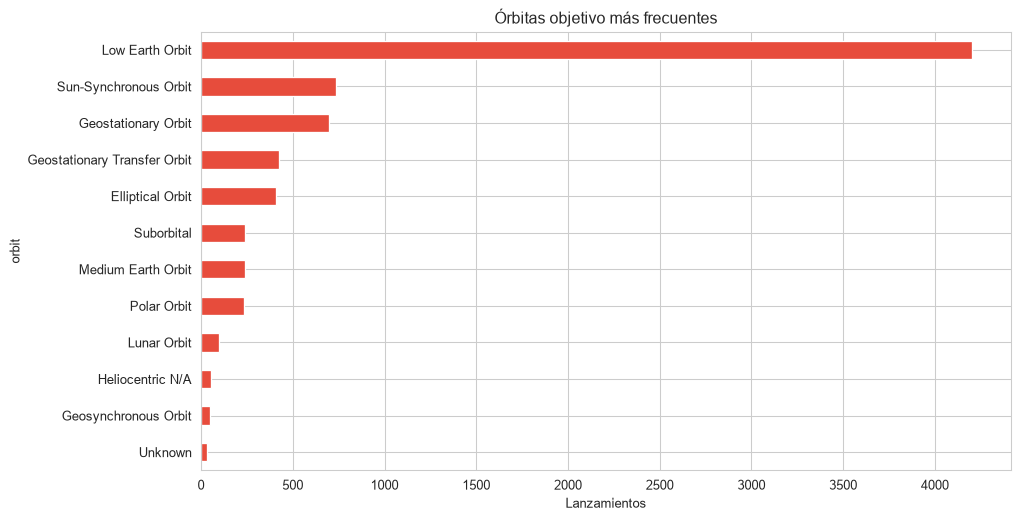

In [14]:
orbits = launch["orbit"].value_counts().head(12)
orbits.plot(kind="barh", color="#e74c3c", figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Órbitas objetivo más frecuentes")
plt.xlabel("Lanzamientos")
plt.show()


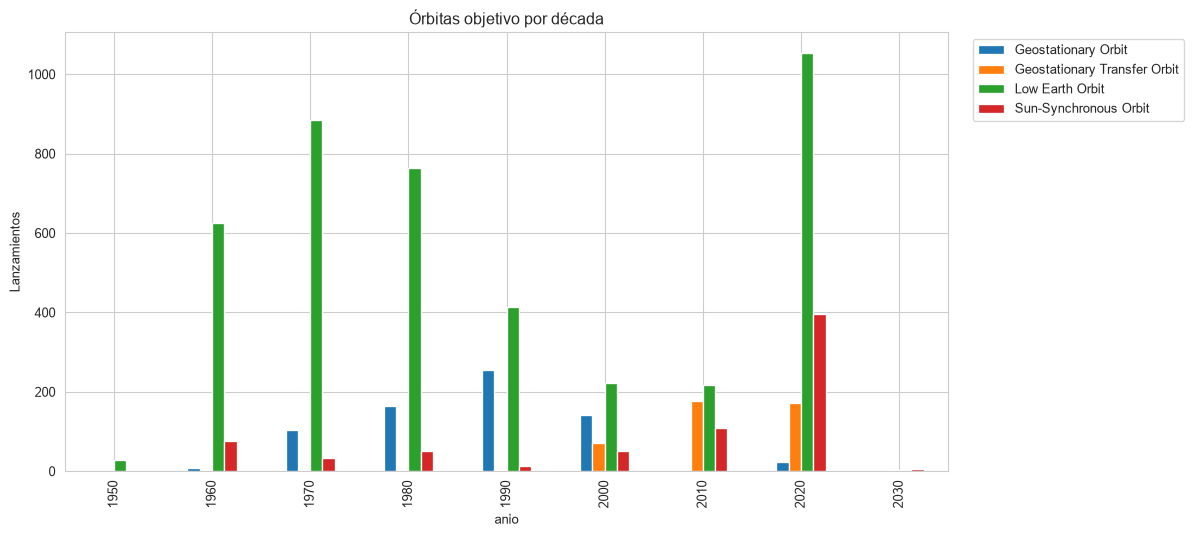

In [15]:
# Órbitas por década (top 4)
orb_dec = launch[launch["orbit"].isin(orbits.index[:4])]
tabla = orb_dec.pivot_table(index=launch["anio"] // 10 * 10,
                            columns="orbit", values="id", aggfunc="count").fillna(0)
tabla.plot(kind="bar", figsize=(12, 6))
plt.title("Órbitas objetivo por década")
plt.ylabel("Lanzamientos")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


**Conclusión 6:** la **órbita terrestre baja (LEO)** concentra el 56 % de los lanzamientos realizados: es donde están la ISS y las constelaciones de satélites. Muy por detrás quedan la órbita geoestacionaria (10 %), la heliosíncrona (9 %), usada para observación de la Tierra, y la de transferencia geoestacionaria (5 %).


## 7. Desde dónde se lanza



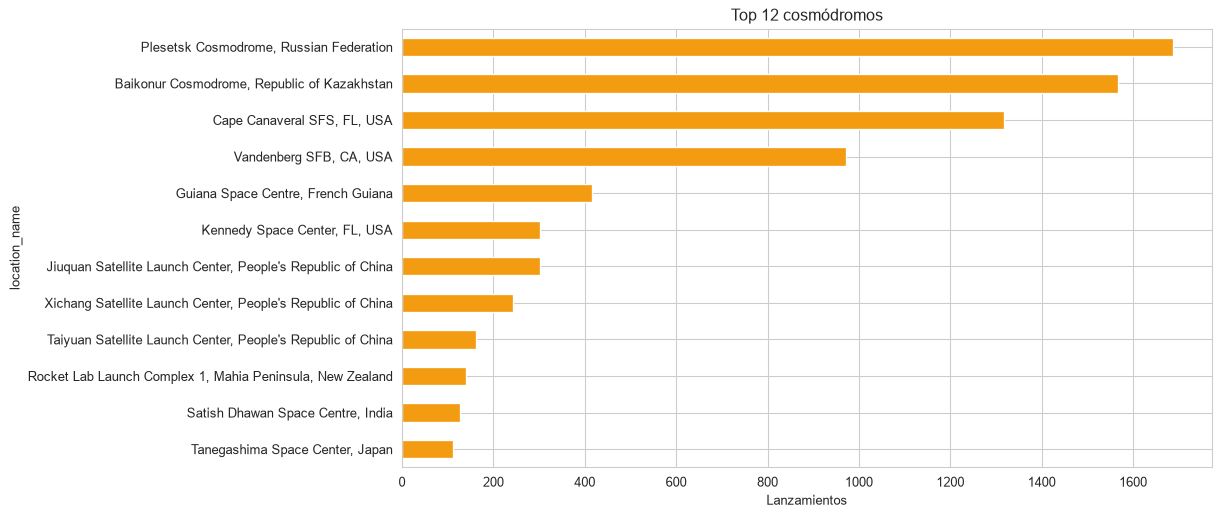

In [16]:
top_sitios = launch["location_name"].value_counts().head(12)
top_sitios.plot(kind="barh", color="#f39c12", figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Top 12 cosmódromos")
plt.xlabel("Lanzamientos")
plt.show()


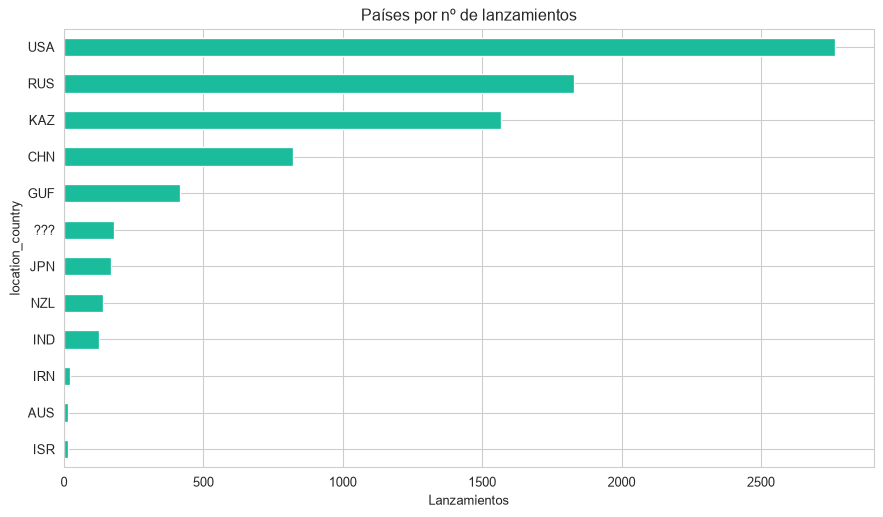

In [17]:
paises = launch["location_country"].value_counts().head(12)
paises.plot(kind="barh", color="#1abc9c", figsize=(11, 6))
plt.gca().invert_yaxis()
plt.title("Países por nº de lanzamientos")
plt.xlabel("Lanzamientos")
plt.show()


**Conclusión 7:** históricamente, los cosmódromos más activos son Plesetsk (1.688 lanzamientos) y Baikonur (1.565), seguidos de Cabo Cañaveral (1.132) y Vandenberg (920). Desde 2021 el mapa ha cambiado: lideran Cabo Cañaveral (321) y Vandenberg (233), y el primero no estadounidense es Jiuquan, en China (165).


## 8. Tipos de misión y programas



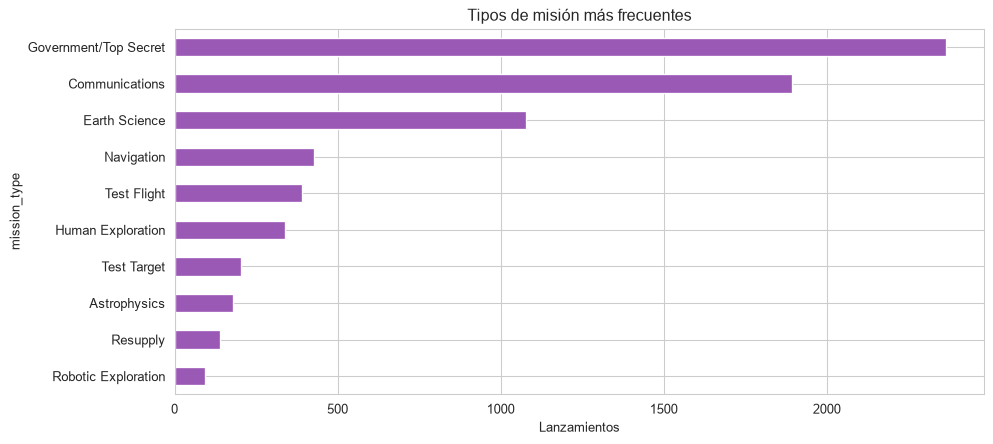

In [18]:
tipos = launch["mission_type"].value_counts().head(10)
tipos.plot(kind="barh", color="#9b59b6", figsize=(11, 5))
plt.gca().invert_yaxis()
plt.title("Tipos de misión más frecuentes")
plt.xlabel("Lanzamientos")
plt.show()


In [19]:
# Programas más repetidos (ej: Starlink, ISS...)
programas = launch["programs"].dropna().str.split(", ")
from collections import Counter
contador = Counter(p for lista in programas for p in lista)
pd.Series(contador).sort_values(ascending=False).head(10)


Starlink                        429
International Space Station     316
Soyuz                           200
Space Shuttle                   135
Amazon Leo                      108
Mir                             108
Global Positioning System        81
GLONASS                          64
Commercial Resupply Services     62
Salyut                           54
dtype: int64

**Conclusión 8:** hasta 1970 la mayoría de las misiones eran gubernamentales o secretas. En la década de 2020 dominan las comunicaciones (659 lanzamientos), impulsadas por las megaconstelaciones: el programa **Starlink** suma por sí solo 429 lanzamientos.


## 9. Personas en el espacio: los astronautas



862 astronautas registrados


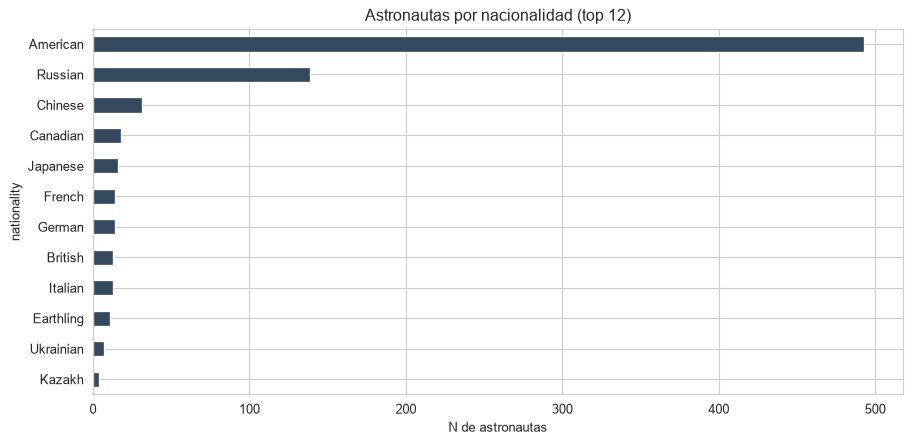

In [20]:
ast = query("SELECT * FROM astronauts")
print(f"{len(ast)} astronautas registrados")

if not ast.empty:
    nat = ast["nationality"].value_counts().head(12)
    if not nat.empty:
        nat.plot(kind="barh", color="#34495e", figsize=(11, 5))
        plt.gca().invert_yaxis()
        plt.title("Astronautas por nacionalidad (top 12)")
        plt.xlabel("N de astronautas")
        plt.show()
else:
    print("Aun no hay astronautas registrados en la base de datos.")


In [21]:
print(ast["status"].value_counts())
# El listado de astronautas de la API v2.0.0 no incluye el número de vuelos:
# se analiza la década del primer vuelo.
primer = pd.to_datetime(ast["first_flight"], errors="coerce", utc=True).dt.year
(primer // 10 * 10).value_counts().sort_index()


status
Retired                         384
Active                          164
Deceased                        128
Occasional Spaceflight          124
In-Training                      24
Lost In Flight                   20
Lost In Training                  8
Died While In Active Service      7
Dismissed                         2
Resigned during Training          1
Name: count, dtype: int64


first_flight
1960.0     54
1970.0     47
1980.0    132
1990.0    168
2000.0    118
2010.0     69
2020.0    217
Name: count, dtype: int64

**Conclusión 9:** hay 862 astronautas registrados de 68 nacionalidades, aunque EE. UU. (493) y Rusia (139) suman tres de cada cuatro. China (31) es ya la tercera nacionalidad. Hoy hay 164 astronautas en activo y 124 con vuelos ocasionales, la categoría que recoge buena parte de los vuelos privados.


## 10. Próximos lanzamientos

¿Qué nos espera en los próximos meses?


In [22]:
ahora = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
proximos = launch[launch["net"] > ahora].sort_values("net")
print(f"{len(proximos)} lanzamientos previstos a partir de hoy")
proximos[["name", "net", "rocket_name", "agency_name", "status_name"]].head(15)


472 lanzamientos previstos a partir de hoy


,name,net,rocket_name,agency_name,status_name
7648,Falcon 9 Block 5 | Starlink Group 15-16,2026-10-27T04:45:00Z,Falcon 9,SpaceX,Go
7649,Falcon 9 Block 5 | Starlink Group 15-18,2026-10-30T04:02:00Z,Falcon 9,SpaceX,Go
7650,GSLV Mk II | IRNSS-1L (NVS-03),2026-10-30T17:00:00Z,GSLV Mk II,Indian Space Research Organization,TBD
7651,Long March 12A | Flight 2,2026-10-31T00:00:00Z,Long March 12A,China Aerospace Science and Technology Corpora...,TBD
7652,Electron | The Sea God Surveys (iQPS Launch 9),2026-11-03T00:00:00Z,Electron,Rocket Lab,TBD
7653,Falcon 9 Block 5 | Starlink Group 15-21,2026-11-05T05:14:00Z,Falcon 9,SpaceX,Go
7654,Falcon 9 Block 5 | NROL-195,2026-11-05T22:34:00Z,Falcon 9,SpaceX,TBD
7655,Electron | The Mountain God Rises (iQPS Launch...,2026-11-10T00:00:00Z,Electron,Rocket Lab,TBD
7656,Ariane 64 Block 2 | Amazon Leo (LE-04),2026-11-23T00:00:00Z,Ariane 64,Arianespace,TBD
7657,Soyuz 2.1b | Progress MS-36 (97P),2026-11-24T05:03:00Z,Soyuz 2.1b,Russian Federal Space Agency (ROSCOSMOS),TBD


**Conclusión 10:** en los próximos 90 días hay 105 lanzamientos programados, liderados por SpaceX (37), United Launch Alliance (20) y Rocket Lab (11). El ritmo actual ronda el centenar de lanzamientos por trimestre.


## 11. Resumen de conclusiones

1. **Récord de actividad:** 341 lanzamientos en 2025, más del doble que en el pico de la carrera espacial (146 en 1967).
2. **Fiabilidad:** el 92,7 % de los lanzamientos realizados ha tenido éxito, y desde los años 70 la tasa se mantiene por encima del 93 %.
3. **Dominio de SpaceX:** desde 2021 lanza más que sus cuatro siguientes competidores juntos, y Falcon 9 es a la vez el cohete más usado y el más fiable (99,4 %).
4. **La órbita baja manda:** el 56 % de los lanzamientos va a LEO; Starlink suma por sí solo 429.
5. **Geografía:** Plesetsk y Baikonur dominan el histórico; hoy lideran Cabo Cañaveral y Vandenberg, con China en ascenso.
6. **Personas en el espacio:** 862 astronautas de 68 nacionalidades, con EE. UU. y Rusia como mayoría.

Estos datos alimentan la app **Órbita** (Streamlit) y el chat que permite preguntarles en lenguaje natural.
